<a href="https://colab.research.google.com/github/Joel-Roy-2004/-NLP-driven-classification-model./blob/main/Donors_Choose_dataset_NLP_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Install library

In [18]:
!pip -q install -U gensim beautifulsoup4 kagglehub

# Imports

In [19]:
import os
import re
import ast
import gc
import glob
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from collections import Counter

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)

import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Concatenate
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from gensim.models import Word2Vec
import gensim.downloader as api


# Loading the dataset

In [20]:
DATASET_HANDLE = "arunasivapragasam/donors-choose"

def find_csv_files(root):
    return sorted(glob.glob(os.path.join(root, "**", "*.csv"), recursive=True))

csv_files = []

try:
    import kagglehub
    dataset_path = kagglehub.dataset_download(DATASET_HANDLE)
    print("Kaggle dataset path:", dataset_path)
    csv_files = find_csv_files(dataset_path)
except Exception as e:
    print("Automatic Kaggle download failed:", repr(e))
    print("Use the upload cell below.")

if not csv_files:
    from google.colab import files
    print("Upload the DonorsChoose CSV file.")
    uploaded = files.upload()
    csv_files = [os.path.abspath(name) for name in uploaded.keys() if name.lower().endswith(".csv")]

print("CSV files found:")
for f in csv_files:
    print(" -", f)


Using Colab cache for faster access to the 'donors-choose' dataset.
Kaggle dataset path: /kaggle/input/donors-choose
CSV files found:
 - /kaggle/input/donors-choose/Preprocessed_DonorsChoose_dataset.csv


In [21]:
TARGET_CANDIDATES = [
    "project_is_approved", "funded", "is_funded", "funding_status",
    "funded_flag", "approved"
]

def inspect_csv(path):
    try:
        sample = pd.read_csv(path, nrows=5)
        return sample.columns.tolist()
    except Exception:
        return []

selected_file = None
selected_cols = None

for path in csv_files:
    cols = inspect_csv(path)
    lower_map = {str(c).lower(): c for c in cols}
    if any(t in lower_map for t in TARGET_CANDIDATES):
        selected_file = path
        selected_cols = cols
        break

if selected_file is None:
    # Fallback: choose the largest CSV
    selected_file = max(csv_files, key=os.path.getsize)
    selected_cols = inspect_csv(selected_file)

print("Selected file:", selected_file)
print("Columns preview:", selected_cols[:30])

df = pd.read_csv(selected_file)
print("Shape:", df.shape)
df.head()

Selected file: /kaggle/input/donors-choose/Preprocessed_DonorsChoose_dataset.csv
Columns preview: ['id', 'teacher_prefix', 'school_state', 'project_grade_category', 'project_subject_categories', 'project_subject_subcategories', 'teacher_number_of_previously_posted_projects', 'project_is_approved', 'price', 'quantity', 'cleaned_titles', 'cleaned_essays', 'cleaned_summary', 'isdigit_summary']
Shape: (109248, 14)


,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


# Data exploration

In [22]:
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes)

print("\nMissing values — top 20:")
display(df.isna().sum().sort_values(ascending=False).head(20))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFirst 5 rows:")
display(df.head())


Shape: (109248, 14)

Data types:


,0
id,object
teacher_prefix,object
school_state,object
project_grade_category,object
project_subject_categories,object
project_subject_subcategories,object
teacher_number_of_previously_posted_projects,int64
project_is_approved,int64
price,float64
quantity,int64



Missing values — top 20:


,0
cleaned_titles,43
id,0
school_state,0
project_grade_category,0
project_subject_categories,0
teacher_prefix,0
project_subject_subcategories,0
teacher_number_of_previously_posted_projects,0
price,0
project_is_approved,0



Duplicate rows: 0

First 5 rows:


,id,teacher_prefix,school_state,project_grade_category,project_subject_categories,project_subject_subcategories,teacher_number_of_previously_posted_projects,project_is_approved,price,quantity,cleaned_titles,cleaned_essays,cleaned_summary,isdigit_summary
0,p253737,mrs,in,grades_prek_2,literacy_language,esl_literacy,0,0,154.60,23,educational support english learners home,students english learners working english seco...,students_need_opportunities_practice_beginning...,0
1,p258326,mr,fl,grades_6_8,history_civics_health_sports,civics_government_teamsports,7,1,299.00,1,wanted projector hungry learners,students arrive school eager learn polite gene...,students_need_projector_help_viewing_education...,0
2,p182444,ms,az,grades_6_8,health_sports,health_wellness_teamsports,1,0,516.85,22,soccer equipment awesome middle school students,true champions not always ones win guts mia ha...,students_need_shine_guards_athletic_socks_socc...,0
3,p246581,mrs,ky,grades_prek_2,literacy_language_math_science,literacy_mathematics,4,1,232.90,4,techie kindergarteners,work unique school filled esl english second l...,students_need_engage_reading_math_way_inspire_...,0
4,p104768,mrs,tx,grades_prek_2,math_science,mathematics,1,1,67.98,4,interactive math tools,second grade classroom next year made around 2...,students_need_hands_practice_mathematics_fun_p...,0


Selecting the target and available text fields

In [23]:
# Identify text columns automatically

target_col = "project_is_approved"

# Exclude target column
available_cols = df.drop(columns=[target_col]).columns

# Find object/string columns
text_cols = [
    col for col in available_cols
    if df[col].dtype == "object" or
       str(df[col].dtype).startswith("string")
]

# Exclude columns that are unlikely to contain useful text
exclude_cols = [
    "id",
    "teacher_id",
    "school_id",
    "project_id"
]

text_cols = [
    col for col in text_cols
    if col.lower() not in exclude_cols
]

print("Text columns found:")
print(text_cols)

if not text_cols:
    raise ValueError("No text columns detected. Please inspect df.columns.")

# Combine all available text columns
df["combined_text"] = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1)

print("\nSample combined text:")
print(df["combined_text"].iloc[0])

Text columns found:
['teacher_prefix', 'school_state', 'project_grade_category', 'project_subject_categories', 'project_subject_subcategories', 'cleaned_titles', 'cleaned_essays', 'cleaned_summary']

Sample combined text:
mrs in grades_prek_2 literacy_language esl_literacy educational support english learners home students english learners working english second third languages melting pot refugees immigrants native born americans bringing gift language school 24 languages represented english learner program students every level mastery also 40 countries represented families within school student brings wealth knowledge experiences us open eyes new cultures beliefs respect limits language limits world ludwig wittgenstein english learner strong support system home begs resources many times parents learning read speak english along side children sometimes creates barriers parents able help child learn phonetics letter recognition reading skills providing dvd players students able continu

In [24]:
print(df[["combined_text", target_col]].head())

print("\nMissing values:")
print(df["combined_text"].isnull().sum())

print("\nTarget distribution:")
print(df[target_col].value_counts())

                                       combined_text  project_is_approved
0  mrs in grades_prek_2 literacy_language esl_lit...                    0
1  mr fl grades_6_8 history_civics_health_sports ...                    1
2  ms az grades_6_8 health_sports health_wellness...                    0
3  mrs ky grades_prek_2 literacy_language_math_sc...                    1
4  mrs tx grades_prek_2 math_science mathematics ...                    1

Missing values:
0

Target distribution:
project_is_approved
1    92706
0    16542
Name: count, dtype: int64


In [25]:
df.columns

Index(['id', 'teacher_prefix', 'school_state', 'project_grade_category',
       'project_subject_categories', 'project_subject_subcategories',
       'teacher_number_of_previously_posted_projects', 'project_is_approved',
       'price', 'quantity', 'cleaned_titles', 'cleaned_essays',
       'cleaned_summary', 'isdigit_summary', 'combined_text'],
      dtype='object')

In [26]:
# Target column
target_col = "project_is_approved"

# Select cleaned text columns
text_cols = [
    "cleaned_titles",
    "cleaned_essays",
    "cleaned_summary"
]

# Verify columns
for col in text_cols:
    if col not in df.columns:
        raise ValueError(f"{col} is missing from dataset")

print("Target column:", target_col)
print("Text columns used:", text_cols)

# Handle missing values
df[text_cols] = df[text_cols].fillna("")

# Combine text fields
df["combined_text"] = (
    df["cleaned_titles"].astype(str) + " " +
    df["cleaned_essays"].astype(str) + " " +
    df["cleaned_summary"].astype(str)
)

print("\nCombined text:")
print(df["combined_text"].head())

Target column: project_is_approved
Text columns used: ['cleaned_titles', 'cleaned_essays', 'cleaned_summary']

Combined text:
0    educational support english learners home stud...
1    wanted projector hungry learners students arri...
2    soccer equipment awesome middle school student...
3    techie kindergarteners work unique school fill...
4    interactive math tools second grade classroom ...
Name: combined_text, dtype: object


In [27]:
X = df["combined_text"]
y = df["project_is_approved"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (109248,)
y shape: (109248,)

Target distribution:
project_is_approved
1    92706
0    16542
Name: count, dtype: int64


TEXT COLUMN SELECTION AND COMBINATION

In [28]:



import pandas as pd

# Check dataset
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

# Target
target_col = "project_is_approved"

# Explicit text columns
text_cols = [
    "cleaned_titles",
    "cleaned_essays",
    "cleaned_summary"
]

# Verify target
assert target_col in df.columns, "Target column not found!"

# Verify text columns
missing_cols = [col for col in text_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"Missing text columns: {missing_cols}")

# Fill missing values
for col in text_cols:
    df[col] = df[col].fillna("").astype(str)

# Combine text
df["combined_text"] = df[text_cols].agg(" ".join, axis=1)

# Prepare features and target
X = df["combined_text"]
y = df[target_col].astype(int)

print("\nText columns used:", text_cols)
print("Target column:", target_col)
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nSample text:")
print(X.iloc[0][:500])

Dataset shape: (109248, 15)

Available columns:
['id', 'teacher_prefix', 'school_state', 'project_grade_category', 'project_subject_categories', 'project_subject_subcategories', 'teacher_number_of_previously_posted_projects', 'project_is_approved', 'price', 'quantity', 'cleaned_titles', 'cleaned_essays', 'cleaned_summary', 'isdigit_summary', 'combined_text']

Text columns used: ['cleaned_titles', 'cleaned_essays', 'cleaned_summary']
Target column: project_is_approved
X shape: (109248,)
y shape: (109248,)

Target distribution:
project_is_approved
1    92706
0    16542
Name: count, dtype: int64

Sample text:
educational support english learners home students english learners working english second third languages melting pot refugees immigrants native born americans bringing gift language school 24 languages represented english learner program students every level mastery also 40 countries represented families within school student brings wealth knowledge experiences us open eyes new cul

# Checking Class balance

project_is_approved
0    16542
1    92706
Name: count, dtype: int64


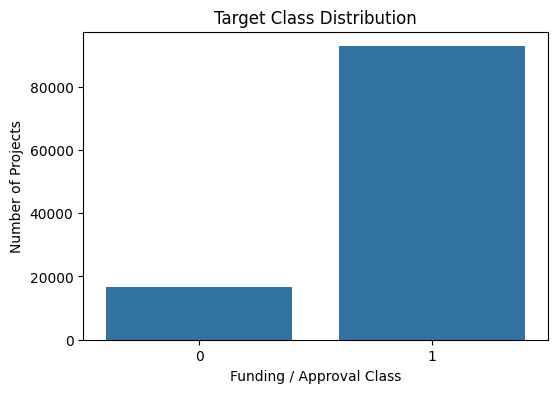

,percentage
project_is_approved,
0,15.14
1,84.86


Class imbalance ratio (majority/minority): 5.60


In [29]:
target_counts = df[target_col].value_counts(dropna=False).sort_index()
print(target_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target_col)
plt.title("Target Class Distribution")
plt.xlabel("Funding / Approval Class")
plt.ylabel("Number of Projects")
plt.show()

class_percent = (target_counts / target_counts.sum() * 100).round(2)
display(class_percent.rename("percentage").to_frame())

imbalance_ratio = target_counts.max() / target_counts.min()
print(f"Class imbalance ratio (majority/minority): {imbalance_ratio:.2f}")

# Text preprocessing

In [30]:
import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

STOP_WORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()

def clean_text(text):
    text = "" if pd.isna(text) else str(text)
    text = BeautifulSoup(text, "html.parser").get_text(" ")
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = re.findall(r"[a-z]+", text)
    tokens = [tok for tok in tokens if tok not in STOP_WORDS and len(tok) > 1]
    return " ".join(tokens)

# Combine all available text fields.
df["combined_text_raw"] = (
    df[text_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

df["clean_text"] = df["combined_text_raw"].map(clean_text)

# Remove rows where target/text is unusable.
df = df.dropna(subset=[target_col]).copy()
df = df[df["clean_text"].str.len() > 0].copy()

# Convert target to 0/1 if it is boolean/string/numeric.
if not pd.api.types.is_numeric_dtype(df[target_col]):
    mapping = {
        "approved": 1, "funded": 1, "yes": 1, "true": 1, "1": 1,
        "rejected": 0, "not funded": 0, "no": 0, "false": 0, "0": 0
    }
    df["_target_norm"] = (
        df[target_col].astype(str).str.strip().str.lower().map(mapping)
    )
    if df["_target_norm"].isna().any():
        print("Unmapped target values:", df.loc[df["_target_norm"].isna(), target_col].unique()[:20])
        raise ValueError("Please define a mapping for the target values.")
    y = df["_target_norm"].astype(int).to_numpy()
else:
    y = df[target_col].astype(int).to_numpy()

X_text = df["clean_text"].to_numpy()

print("Final modeling rows:", len(df))
display(df[["combined_text_raw", "clean_text"]].head(3))

Final modeling rows: 109248


,combined_text_raw,clean_text
0,educational support english learners home stud...,educational support english learners home stud...
1,wanted projector hungry learners students arri...,wanted projector hungry learners students arri...
2,soccer equipment awesome middle school student...,soccer equipment awesome middle school student...


# Optional lemmatization demonstration

In [31]:
print("Dataset shape:", df.shape)
print("Clean text column exists:", "clean_text" in df.columns)

if "clean_text" in df.columns:
    print("Non-null values:", df["clean_text"].notna().sum())
    print(df["clean_text"].head())

Dataset shape: (109248, 17)
Clean text column exists: True
Non-null values: 109248
0    educational support english learners home stud...
1    wanted projector hungry learners students arri...
2    soccer equipment awesome middle school student...
3    techie kindergarteners work unique school fill...
4    interactive math tools second grade classroom ...
Name: clean_text, dtype: object


In [32]:
example_tokens = df["clean_text"].iloc[0].split()[:30]
example_lemmas = [LEMMATIZER.lemmatize(tok) for tok in example_tokens]

print("Before:", example_tokens)
print("After :", example_lemmas)

Before: ['educational', 'support', 'english', 'learners', 'home', 'students', 'english', 'learners', 'working', 'english', 'second', 'third', 'languages', 'melting', 'pot', 'refugees', 'immigrants', 'native', 'born', 'americans', 'bringing', 'gift', 'language', 'school', 'languages', 'represented', 'english', 'learner', 'program', 'students']
After : ['educational', 'support', 'english', 'learner', 'home', 'student', 'english', 'learner', 'working', 'english', 'second', 'third', 'language', 'melting', 'pot', 'refugee', 'immigrant', 'native', 'born', 'american', 'bringing', 'gift', 'language', 'school', 'language', 'represented', 'english', 'learner', 'program', 'student']


# Train , Test and Validation

In [34]:
SEED = 42  # Define the random seed

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y, test_size=0.30, random_state=SEED, stratify=y
)

X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Train:", len(X_train_text))
print("Validation:", len(X_val_text))
print("Test:", len(X_test_text))

print("\nClass ratios:")
print("Train:", np.mean(y_train))
print("Val  :", np.mean(y_val))
print("Test :", np.mean(y_test))

Train: 76473
Validation: 16387
Test: 16388

Class ratios:
Train: 0.8485870830227662
Val  : 0.8485994996033441
Test : 0.8485477178423236


# TF-IDF embedding

In [35]:
TFIDF_MAX_FEATURES = 20000

tfidf_results = []

for ngram_range in [(1, 1), (1, 2), (1, 3)]:
    vectorizer_tmp = TfidfVectorizer(
        ngram_range=ngram_range,
        min_df=3,
        max_df=0.95,
        max_features=TFIDF_MAX_FEATURES,
        sublinear_tf=True
    )
    Xtr = vectorizer_tmp.fit_transform(X_train_text)
    Xv = vectorizer_tmp.transform(X_val_text)

    model_tmp = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=1.0,
        solver="liblinear",
        random_state=SEED
    )
    model_tmp.fit(Xtr, y_train)
    pred = model_tmp.predict(Xv)
    prob = model_tmp.predict_proba(Xv)[:, 1]

    tfidf_results.append({
        "ngram_range": str(ngram_range),
        "features": Xtr.shape[1],
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, prob)
    })

tfidf_results_df = pd.DataFrame(tfidf_results)
display(tfidf_results_df)


,ngram_range,features,accuracy,precision,recall,f1,roc_auc
0,"(1, 1)",20000,0.702691,0.903953,0.726880,0.805804,0.701247
1,"(1, 2)",20000,0.712882,0.901405,0.742917,0.814523,0.702129
2,"(1, 3)",20000,0.710746,0.900262,0.741263,0.813062,0.701452


Final TF-IDF representation

In [36]:
best_ngram = ast.literal_eval(tfidf_results_df.sort_values("f1", ascending=False).iloc[0]["ngram_range"])
print("Selected n-gram range:", best_ngram)

tfidf = TfidfVectorizer(
    ngram_range=best_ngram,
    min_df=3,
    max_df=0.95,
    max_features=TFIDF_MAX_FEATURES,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("TF-IDF train shape:", X_train_tfidf.shape)
print("TF-IDF validation shape:", X_val_tfidf.shape)
print("TF-IDF test shape:", X_test_tfidf.shape)


Selected n-gram range: (1, 2)
TF-IDF train shape: (76473, 20000)
TF-IDF validation shape: (16387, 20000)
TF-IDF test shape: (16388, 20000)


# Word2Vec document embeddings

In [37]:
train_tokens = [text.split() for text in X_train_text]

w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=3,
    workers=max(1, os.cpu_count() // 2),
    sg=0,              # CBOW
    epochs=8,
    seed=SEED
)

print("Word2Vec vocabulary size:", len(w2v_model.wv))
print("Embedding dimension:", w2v_model.wv.vector_size)

Word2Vec vocabulary size: 26551
Embedding dimension: 100


Optional pre-trained Google News Word2Vec

In [38]:
USE_GOOGLE_NEWS = False

google_w2v = None

if USE_GOOGLE_NEWS:
    try:
        google_w2v = api.load("word2vec-google-news-300")
        print("Google News Word2Vec loaded.")
    except Exception as e:
        print("Could not load Google News Word2Vec:", repr(e))
        print("Continuing with the dataset-trained Word2Vec model.")

Optional smaller pre-trained static embeddings

In [39]:
USE_PRETRAINED_GLOVE = True
pretrained_model = None

if USE_PRETRAINED_GLOVE:
    try:
        pretrained_model = api.load("glove-wiki-gigaword-100")
        print("Pre-trained GloVe-100 loaded.")
    except Exception as e:
        print("Could not download GloVe-100:", repr(e))
        print("Continuing without the optional pre-trained embedding experiment.")

def pretrained_document_vector(text, model):
    tokens = text.split()
    vectors = [model[word] for word in tokens if word in model]
    if not vectors:
        return np.zeros(model.vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0).astype(np.float32)

if pretrained_model is not None:
    X_train_pre = np.vstack([pretrained_document_vector(t, pretrained_model) for t in X_train_text])
    X_val_pre = np.vstack([pretrained_document_vector(t, pretrained_model) for t in X_val_text])
    X_test_pre = np.vstack([pretrained_document_vector(t, pretrained_model) for t in X_test_text])

    pre_lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
    pre_lr.fit(X_train_pre, y_train)
    pre_prob = pre_lr.predict_proba(X_test_pre)[:, 1]
    pre_pred = (pre_prob >= 0.5).astype(int)

    print(classification_report(y_test, pre_pred, digits=4))
    print("Pre-trained GloVe experiment completed.")

[==================================================] 100.0% 128.1/128.1MB downloaded
Pre-trained GloVe-100 loaded.
              precision    recall  f1-score   support

           0     0.2367    0.6426    0.3459      2482
           1     0.9081    0.6301    0.7440     13906

    accuracy                         0.6320     16388
   macro avg     0.5724    0.6364    0.5450     16388
weighted avg     0.8064    0.6320    0.6837     16388

Pre-trained GloVe experiment completed.


Convert each document into a Word2Vec vector

In [40]:
def document_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]
    if not vectors:
        return np.zeros(model.wv.vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0).astype(np.float32)

def make_w2v_features(texts, model):
    return np.vstack([
        document_vector(text.split(), model)
        for text in texts
    ]).astype(np.float32)

X_train_w2v = make_w2v_features(X_train_text, w2v_model)
X_val_w2v = make_w2v_features(X_val_text, w2v_model)
X_test_w2v = make_w2v_features(X_test_text, w2v_model)

print("Word2Vec train shape:", X_train_w2v.shape)

Word2Vec train shape: (76473, 100)


# Classical ML — Logistic Regression

In [41]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

lr_grid = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    ),
    param_grid={"C": [0.1, 1.0, 3.0]},
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train_tfidf, y_train)

print("Best Logistic Regression parameters:", lr_grid.best_params_)
print("Best CV F1:", lr_grid.best_score_)

lr_model = lr_grid.best_estimator_
lr_val_prob = lr_model.predict_proba(X_val_tfidf)[:, 1]
lr_test_prob = lr_model.predict_proba(X_test_tfidf)[:, 1]
lr_test_pred = (lr_test_prob >= 0.5).astype(int)

print(classification_report(y_test, lr_test_pred, digits=4))

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Logistic Regression parameters: {'C': 3.0}
Best CV F1: 0.8278323180649781
              precision    recall  f1-score   support

           0     0.2809    0.5363    0.3687      2482
           1     0.9012    0.7550    0.8216     13906

    accuracy                         0.7219     16388
   macro avg     0.5911    0.6456    0.5952     16388
weighted avg     0.8073    0.7219    0.7530     16388



# Classical ML — Linear SVM

In [42]:
svm_grid = GridSearchCV(
    estimator=LinearSVC(class_weight="balanced", random_state=SEED),
    param_grid={"C": [0.1, 0.5, 1.0, 2.0]},
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train_tfidf, y_train)

print("Best SVM parameters:", svm_grid.best_params_)
print("Best CV F1:", svm_grid.best_score_)

svm_model = svm_grid.best_estimator_
svm_test_score = svm_model.decision_function(X_test_tfidf)
svm_test_pred = (svm_test_score >= 0).astype(int)

print(classification_report(y_test, svm_test_pred, digits=4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best SVM parameters: {'C': 2.0}
Best CV F1: 0.8281177704014588
              precision    recall  f1-score   support

           0     0.2596    0.4831    0.3377      2482
           1     0.8910    0.7541    0.8169     13906

    accuracy                         0.7131     16388
   macro avg     0.5753    0.6186    0.5773     16388
weighted avg     0.7954    0.7131    0.7443     16388



# Reusable evaluation function

In [43]:
def evaluate_model(name, y_true, y_pred, scores):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "PR-AUC": average_precision_score(y_true, scores)
    }

results = []

results.append(evaluate_model(
    "Logistic Regression + TF-IDF",
    y_test, lr_test_pred, lr_test_prob
))

results.append(evaluate_model(
    "Linear SVM + TF-IDF",
    y_test, svm_test_pred, svm_test_score
))

display(pd.DataFrame(results).sort_values("F1", ascending=False))

if pretrained_model is not None:
    results.append(evaluate_model(
        "Logistic Regression + Pre-trained GloVe",
        y_test, pre_pred, pre_prob
    ))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression + TF-IDF,0.721870,0.901202,0.754998,0.821647,0.700784,0.918463
1,Linear SVM + TF-IDF,0.713083,0.890994,0.754135,0.816872,0.661777,0.906517


# Confusion matrices

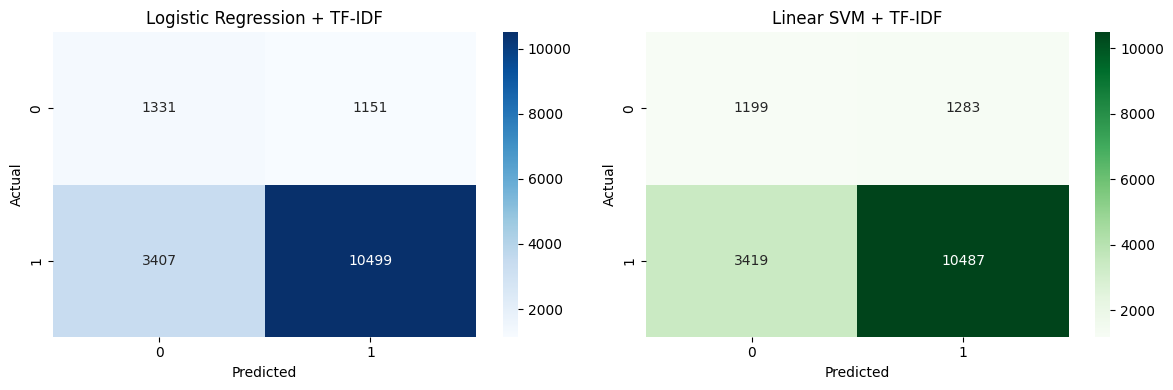

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm_lr = confusion_matrix(y_test, lr_test_pred)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Logistic Regression + TF-IDF")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

cm_svm = confusion_matrix(y_test, svm_test_pred)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Linear SVM + TF-IDF")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# ROC curve and Precision-Recall curve — classical models

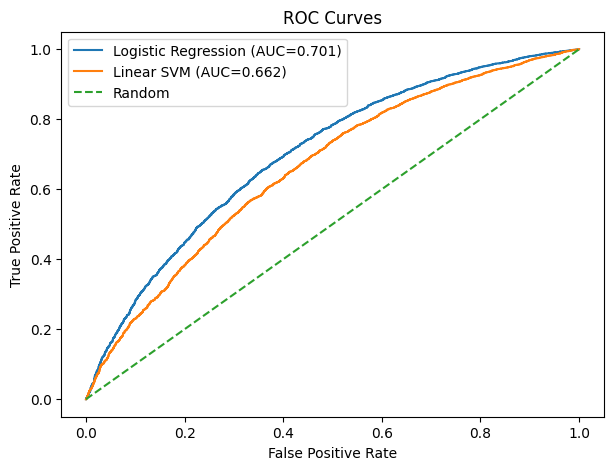

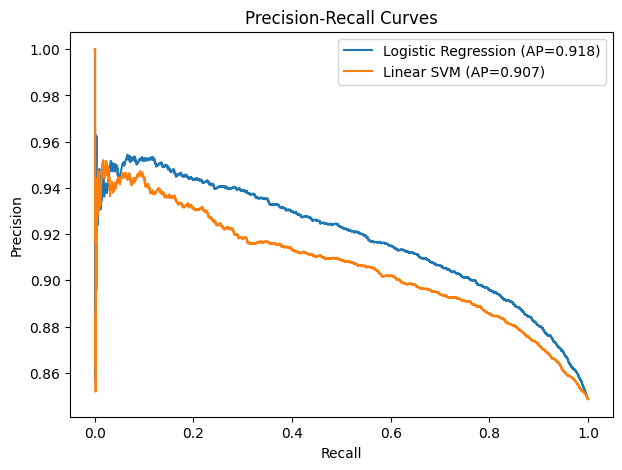

In [45]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_test_prob)
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_test_score)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={roc_auc_score(y_test, lr_test_prob):.3f})")
plt.plot(fpr_svm, tpr_svm, label=f"Linear SVM (AUC={roc_auc_score(y_test, svm_test_score):.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

precision_lr, recall_lr, _ = precision_recall_curve(y_test, lr_test_prob)
precision_svm, recall_svm, _ = precision_recall_curve(y_test, svm_test_score)

plt.figure(figsize=(7, 5))
plt.plot(recall_lr, precision_lr, label=f"Logistic Regression (AP={average_precision_score(y_test, lr_test_prob):.3f})")
plt.plot(recall_svm, precision_svm, label=f"Linear SVM (AP={average_precision_score(y_test, svm_test_score):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()

# Deep Learning — Keras Functional API

In [46]:
# A separate, compact TF-IDF representation is used for the neural network.
# Keeping this branch small avoids converting a very large sparse matrix to dense.
DL_TFIDF_MAX_FEATURES = 3000

tfidf_dl = TfidfVectorizer(
    ngram_range=best_ngram,
    min_df=3,
    max_df=0.95,
    max_features=DL_TFIDF_MAX_FEATURES,
    sublinear_tf=True
)

X_train_tfidf_dl = tfidf_dl.fit_transform(X_train_text)
X_val_tfidf_dl = tfidf_dl.transform(X_val_text)
X_test_tfidf_dl = tfidf_dl.transform(X_test_text)

tfidf_dim = X_train_tfidf_dl.shape[1]
w2v_dim = X_train_w2v.shape[1]

X_train_tfidf_dense = X_train_tfidf_dl.toarray().astype(np.float32)
X_val_tfidf_dense = X_val_tfidf_dl.toarray().astype(np.float32)
X_test_tfidf_dense = X_test_tfidf_dl.toarray().astype(np.float32)

print("Deep-learning TF-IDF shape:", X_train_tfidf_dl.shape)
print("Dense TF-IDF memory (approx.):",
      round((X_train_tfidf_dense.nbytes + X_val_tfidf_dense.nbytes + X_test_tfidf_dense.nbytes) / (1024**3), 2),
      "GB")

tfidf_input = Input(shape=(tfidf_dim,), name="tfidf_input")
x1 = Dense(256, activation="relu")(tfidf_input)
x1 = BatchNormalization()(x1)
x1 = Dropout(0.35)(x1)

w2v_input = Input(shape=(w2v_dim,), name="word2vec_input")
x2 = Dense(128, activation="relu")(w2v_input)
x2 = BatchNormalization()(x2)
x2 = Dropout(0.25)(x2)

merged = Concatenate(name="combined_embeddings")([x1, x2])
x = Dense(128, activation="relu")(merged)
x = BatchNormalization()(x)
x = Dropout(0.35)(x)
x = Dense(64, activation="relu")(x)
x = Dropout(0.20)(x)

output = Dense(1, activation="sigmoid", name="funding_output")(x)

functional_model = Model(
    inputs=[tfidf_input, w2v_input],
    outputs=output,
    name="DonorsChoose_TFIDF_Word2Vec_Functional"
)

functional_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

functional_model.summary()

Deep-learning TF-IDF shape: (76473, 3000)
Dense TF-IDF memory (approx.): 1.22 GB


Model: "DonorsChoose_TFIDF_Word2Vec_Functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tfidf_input         │ (None, 3000)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word2vec_input      │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    768,256 │ tfidf_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     12,928 │ word2vec_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_embeddings │ (None, 384)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     49,280 │ combined_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ funding_output      │ (None, 1)         │         65 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 840,833 (3.21 MB)

 Trainable params: 839,809 (3.20 MB)

 Non-trainable params: 1,024 (4.00 KB)

# Train the Functional API model

In [47]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

history = functional_model.fit(
    x={
        "tfidf_input": X_train_tfidf_dense,
        "word2vec_input": X_train_w2v
    },
    y=y_train,
    validation_data=(
        {
            "tfidf_input": X_val_tfidf_dense,
            "word2vec_input": X_val_w2v
        },
        y_val
    ),
    epochs=15,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
598/598 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.8323 - auc: 0.6419 - loss: 0.4345 - precision: 0.8544 - recall: 0.9671 - val_accuracy: 0.8494 - val_auc: 0.7090 - val_loss: 0.3894 - val_precision: 0.8495 - val_recall: 0.9996 - learning_rate: 0.0010
Epoch 2/15
598/598 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8518 - auc: 0.7322 - loss: 0.3798 - precision: 0.8601 - recall: 0.9857 - val_accuracy: 0.8519 - val_auc: 0.7224 - val_loss: 0.3838 - val_precision: 0.8619 - val_recall: 0.9830 - learning_rate: 0.0010
Epoch 3/15
596/598 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8576 - auc: 0.7884 - loss: 0.3519 - precision: 0.8687 - recall: 0.9801
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
598/598 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8572 - auc: 0.7788 - loss: 0.3556 - precision: 0.8686 - recall: 0.9801 - val_accuracy: 0.8506 - val_auc: 0.7131 - val_loss: 0.3905 - val_precision: 0.8643 - val_recall: 0.9773 - learning_rate: 0

# Plot deep-learning training history

dict_keys(['accuracy', 'auc', 'loss', 'precision', 'recall', 'val_accuracy', 'val_auc', 'val_loss', 'val_precision', 'val_recall', 'learning_rate'])


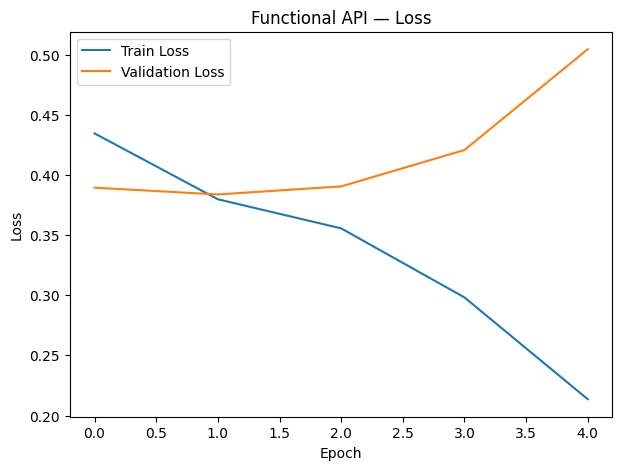

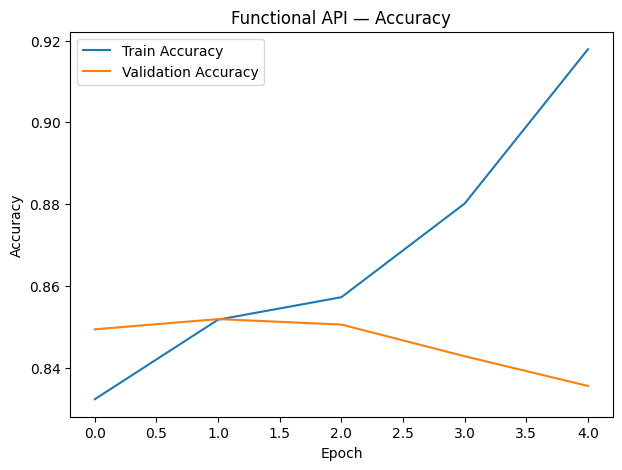

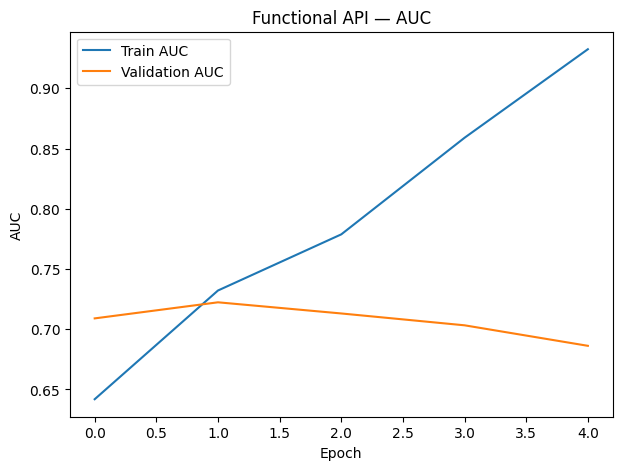

In [48]:
print(history.history.keys())

plt.figure(figsize=(7, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Functional API — Loss")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Functional API — Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(history.history["auc"], label="Train AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Functional API — AUC")
plt.legend()
plt.show()

# Evaluate the Functional API model

In [49]:
dl_test_prob = functional_model.predict(
    {
        "tfidf_input": X_test_tfidf_dense,
        "word2vec_input": X_test_w2v
    },
    batch_size=256,
    verbose=0
).ravel()

dl_test_pred = (dl_test_prob >= 0.5).astype(int)

print(classification_report(y_test, dl_test_pred, digits=4))

results.append(evaluate_model(
    "Functional API: TF-IDF + Word2Vec",
    y_test, dl_test_pred, dl_test_prob
))

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df)

              precision    recall  f1-score   support

           0     0.5554    0.1213    0.1991      2482
           1     0.8624    0.9827    0.9186     13906

    accuracy                         0.8522     16388
   macro avg     0.7089    0.5520    0.5588     16388
weighted avg     0.8159    0.8522    0.8096     16388



,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
3,Functional API: TF-IDF + Word2Vec,0.852209,0.862363,0.982669,0.918594,0.730341,0.926341
0,Logistic Regression + TF-IDF,0.721870,0.901202,0.754998,0.821647,0.700784,0.918463
1,Linear SVM + TF-IDF,0.713083,0.890994,0.754135,0.816872,0.661777,0.906517
2,Logistic Regression + Pre-trained GloVe,0.631987,0.908073,0.630088,0.743961,0.685079,0.912655


# Deep-learning confusion matrix

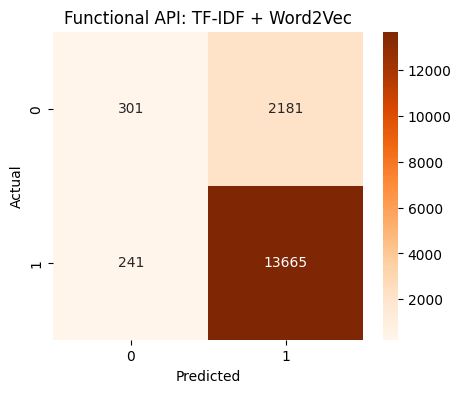

In [50]:
plt.figure(figsize=(5, 4))
cm_dl = confusion_matrix(y_test, dl_test_pred)
sns.heatmap(cm_dl, annot=True, fmt="d", cmap="Oranges")
plt.title("Functional API: TF-IDF + Word2Vec")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Combined ROC and Precision-Recall curves

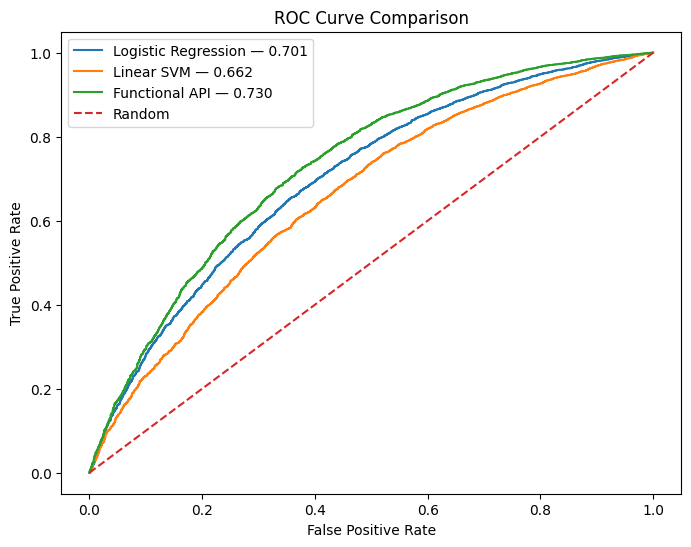

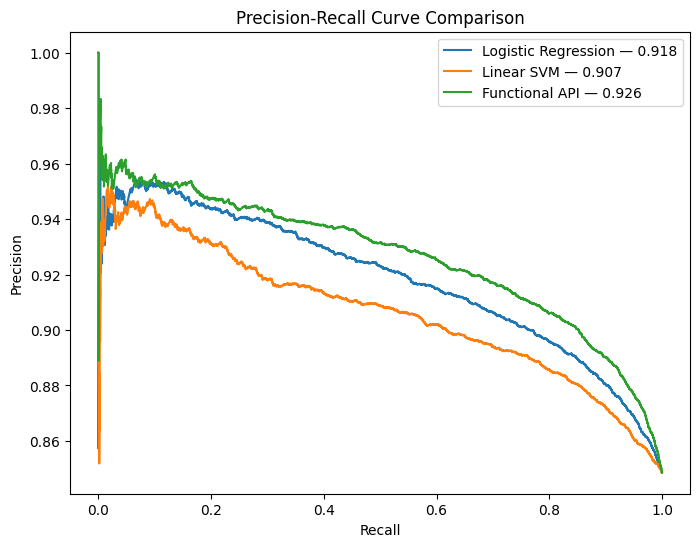

In [51]:
plt.figure(figsize=(8, 6))

fpr_dl, tpr_dl, _ = roc_curve(y_test, dl_test_prob)

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression — {roc_auc_score(y_test, lr_test_prob):.3f}")
plt.plot(fpr_svm, tpr_svm, label=f"Linear SVM — {roc_auc_score(y_test, svm_test_score):.3f}")
plt.plot(fpr_dl, tpr_dl, label=f"Functional API — {roc_auc_score(y_test, dl_test_prob):.3f}")
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

plt.figure(figsize=(8, 6))

precision_dl, recall_dl, _ = precision_recall_curve(y_test, dl_test_prob)

plt.plot(recall_lr, precision_lr, label=f"Logistic Regression — {average_precision_score(y_test, lr_test_prob):.3f}")
plt.plot(recall_svm, precision_svm, label=f"Linear SVM — {average_precision_score(y_test, svm_test_score):.3f}")
plt.plot(recall_dl, precision_dl, label=f"Functional API — {average_precision_score(y_test, dl_test_prob):.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.show()


# Final model comparison

In [52]:
results_df = pd.DataFrame(results).drop_duplicates(subset=["Model"], keep="last")
results_df = results_df.sort_values(["F1", "ROC-AUC"], ascending=False).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

best_model_name = results_df.iloc[0]["Model"]
print("Best model by F1-score:", best_model_name)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Functional API: TF-IDF + Word2Vec,0.8522,0.8624,0.9827,0.9186,0.7303,0.9263
1,Logistic Regression + TF-IDF,0.7219,0.9012,0.7550,0.8216,0.7008,0.9185
2,Linear SVM + TF-IDF,0.7131,0.8910,0.7541,0.8169,0.6618,0.9065
3,Logistic Regression + Pre-trained GloVe,0.6320,0.9081,0.6301,0.7440,0.6851,0.9127


Best model by F1-score: Functional API: TF-IDF + Word2Vec


In [53]:
# Save model comparison
results_df.to_csv("model_comparison.csv", index=False)

# Save a lightweight text file with the selected configuration
with open("experiment_summary.txt", "w", encoding="utf-8") as f:
    f.write(f"Target column: {target_col}\n")
    f.write(f"Text columns: {text_cols}\n")
    f.write(f"Best TF-IDF n-gram: {best_ngram}\n")
    f.write(f"Best model by F1: {best_model_name}\n")
    f.write("\nModel comparison:\n")
    f.write(results_df.to_string(index=False))

print("Saved: model_comparison.csv")
print("Saved: experiment_summary.txt")

Saved: model_comparison.csv
Saved: experiment_summary.txt
